# Funds combined population: discrete intervention dose-response with residual bias correction

**Outcome:** any ED visit in the source `outcome_ed_90d` window (binary, matching the existing
Funds dosage notebook). **X-axis:** exact observed integer intervention count. **Benefit:**
reduction in ED-event risk relative to count zero, in **percentage points**, not visits prevented.

This notebook implements the discrete indicator-basis version of Galagate (2016), equation
(3.7), underlying the R package **causaldrf** residual-correction method. It is a Python
adaptation of the mathematical estimator, not a claim of bit-for-bit R package parity.
No EconML or R installation is required.

The default target is **all eligible rows in the verified Funds training split**, not the
highest-benefit subset. Set `population='all_eligible'` to deliberately target the complete
eligible Funds population instead; that consumes the previous holdout. Each source row has
equal weight. Repeated members are clustered, so this is an average over records, not over
unique people.

Run all cells from the repository root or `Code/`. Results go into a new
`Outputs/Discrete_ADRF_Funds/Python/<population>/` directory. Existing notebooks and model
outputs are only read. No row-level patient predictions are exported by default.

## What is reproduced, and what is adapted?

The source notebook `PRISM_Dosage_Intervention_Counts_Funds.ipynb` supplies the eligibility
rules, source-row alignment, seed-123 70/30 treatment/outcome-stratified split, binary ED
definition, baseline variables, median imputation, missingness indicators, categorical
encoding, and risk-tier normalization. Numeric imputation, scaling, and category learning
are moved **inside each fitting fold** to prevent leakage.

For a discrete count $t$, let $m_t(X)=E[Y\mid T=t,X]$ and $p_t(X)=P(T=t\mid X)$.
The final risk is

$$\widehat\mu(t)=\frac1n\sum_i\left[\widehat m_t(X_i)+
\frac{I(T_i=t)}{\widehat p_t(X_i)}\{Y_i-\widehat m_t(X_i)\}\right].$$

This is exactly the paper's equation (3.7) with $b_t(T)=I(T=t)$, because
$E[bb^\top\mid X]=\operatorname{diag}(p_t(X))$. The paper explicitly permits this basis
in Chapter 3, printed page 50. It estimates a separate mean at each count; it does not assume
a linear dose effect or interpolate across missing counts.

The R `aipwee_est` API supports degree 1 or 2 with OLS outcome regression. This notebook
extends the basis to discrete indicators, uses regularized logistic outcome regressions for
bounded binary-risk predictions, multinomial treatment probabilities, and member-grouped
cross-fitting. A ridge linear-probability sensitivity fit is also reported. The inspected
CRAN source uses an aggregated `Y_hat` in its residual and excludes zero doses when averaging
slope terms; this notebook follows the dissertation's individual fitted residual equation
instead. **It intentionally does not duplicate those R implementation details.**

Corrected row contributions can fall outside [0,1]; they are estimating-function contributions,
not validated individual counterfactual risks. This analysis estimates the population curve.
Double robustness requires correct nuisance models in the appropriate limit plus causal
identification assumptions; regularization and cross-fitting do not guarantee those conditions.

Sources: [dissertation, Chapter 3](https://drum.lib.umd.edu/bitstreams/584a3d22-fffe-4271-8926-5a30a707da1e/download),
[causaldrf 0.4.2 documentation](https://search.r-project.org/CRAN/refmans/causaldrf/html/aipwee_est.html),
[R source inspected](https://github.com/cran/causaldrf/blob/master/R/aipwee_est.R).

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

CODE_DIR = Path.cwd() if (Path.cwd() / '_prism_model_utils.py').exists() else Path.cwd() / 'Code'
if not (CODE_DIR / '_prism_model_utils.py').exists():
    raise FileNotFoundError('Run from the repository root or Code folder.')
ROOT = CODE_DIR.parent
sys.path.insert(0, str(CODE_DIR))
from _prism_model_utils import clean_names_simple, split_train_test, to_binary

CONFIG = {
    'population': 'training',  # or 'all_eligible'; never selects high-benefit members
    'seed': 123, 'folds': 5,
    'minimum_dose_members': 30,  # outcome-blind reporting eligibility
    'minimum_member_ess': 30,
    'low_propensity': 0.01, 'maximum_low_p_fraction': 0.10,
    'maximum_abs_smd': 0.10, 'maximum_member_weight_share': 0.10,
    'propensity_C': 0.2, 'outcome_C': 0.2, 'ridge_alpha': 10.0,
    'multiplier_reps': 1500,
    'small_increment_pp': 1.0,  # illustrative equivalence margin, not a clinical decision rule
    'timing_confirmed': False,
    'run_sensitivities': True, 'write_outputs': True,
}
if CONFIG['population'] not in {'training', 'all_eligible'}:
    raise ValueError('Unknown target population.')
RAW_PATH = ROOT / 'DataSets' / 'Funds_combined.csv'
SCORE_DIR = ROOT / 'Outputs' / 'Causal-Forests_Funds' / 'Python'
FULL_PATH = SCORE_DIR / 'causal_forest_scored_output.csv'
TEST_PATH = SCORE_DIR / 'causal_forest_scored_test_output.csv'
OUTPUT_DIR = ROOT / 'Outputs' / 'Discrete_ADRF_Funds' / 'Python' / CONFIG['population']
for path in (RAW_PATH, FULL_PATH, TEST_PATH):
    if not path.exists():
        raise FileNotFoundError(f'Required source-workflow input missing: {path}')
print('Target:', CONFIG['population'], '| outcome: binary 90-day ED event | dose: intervention count')
print('Outputs:', OUTPUT_DIR)

Target: training | outcome: binary 90-day ED event | dose: intervention count
Outputs: C:\Users\i.Nikesh.Desai\OneDrive - Acentra\Documents\GitHub\prism_repo\Outputs\Discrete_ADRF_Funds\Python\training


## 1. Reconstruct and verify the source population

Treated eligibility is intervention flag 1 without opt-out 1; control eligibility is opt-out
1 without intervention flag 1. The raw source count is the dosage even where the binary
flag disagrees: disagreements are audited and tested separately. Missing counts are **not**
assigned zero. Missing outcomes are filled with zero for main-analysis parity, with a fully
refitted complete-outcome sensitivity analysis below.

In [2]:
raw = pd.read_csv(RAW_PATH)
raw.columns = clean_names_simple(raw.columns)
if raw.columns.duplicated().any():
    raise ValueError('Column cleaning produced duplicate names.')
scored = pd.read_csv(FULL_PATH, usecols=['analysis_row_id', 'member_id', 'intervention_flag', 'outcome_ed_90d'])
saved_test = pd.read_csv(TEST_PATH, usecols=['analysis_row_id', 'member_id'])
required = {'member_id', 'intervention_flag', 'optout_flag', 'outcome_ed_90d', 'interventioncount'}
if not required.issubset(raw):
    raise KeyError(required - set(raw))
source_treatment = to_binary(raw['intervention_flag']).where(lambda s: s.isin([0., 1.]))
source_optout = to_binary(raw['optout_flag']).where(lambda s: s.isin([0., 1.]))
treated = source_treatment.eq(1.) & ~source_optout.eq(1.)
control = source_optout.eq(1.) & ~source_treatment.eq(1.)
eligible = treated | control
raw_model = raw.loc[eligible].reset_index(drop=True)
expected_treatment = np.select([treated, control], [1., 0.], default=np.nan)[eligible.to_numpy()]
expected_outcome = (pd.to_numeric(raw['outcome_ed_90d'], errors='coerce').fillna(0) > 0).astype(float)[eligible].to_numpy()
checks = {
    'cohort size': len(raw_model) == len(scored),
    'sequential row IDs': scored.analysis_row_id.tolist() == list(range(len(scored))),
    'source member order': raw_model.member_id.astype(str).tolist() == scored.member_id.astype(str).tolist(),
    'treatment alignment': np.array_equal(expected_treatment, scored.intervention_flag.to_numpy()),
    'outcome alignment': np.array_equal(expected_outcome, scored.outcome_ed_90d.to_numpy()),
}
if not all(checks.values()):
    raise ValueError(f'Source/scored validation failed: {checks}')
train, reconstructed_test = split_train_test(scored, train_fraction=.70, seed=123,
                                            stratify_columns=['intervention_flag', 'outcome_ed_90d'])
if reconstructed_test.analysis_row_id.tolist() != saved_test.analysis_row_id.tolist():
    raise ValueError('Reconstructed split does not match the saved Funds test rows.')
target = train if CONFIG['population'] == 'training' else scored
cohort = raw_model.iloc[target.analysis_row_id.to_numpy(dtype=int)].copy().reset_index(drop=True)
cohort.insert(0, 'analysis_row_id', target.analysis_row_id.to_numpy(dtype=int))
cohort['received_treatment'] = target.intervention_flag.to_numpy(dtype=int)
if cohort.member_id.isna().any():
    raise ValueError('Missing member IDs prevent grouped fitting and uncertainty estimation.')
raw_count = pd.to_numeric(cohort.interventioncount, errors='coerce')
raw_y = pd.to_numeric(cohort.outcome_ed_90d, errors='coerce')
if ((raw_count.dropna() < 0) | (raw_count.dropna() % 1 != 0)).any() or np.isinf(raw_count.dropna()).any():
    raise ValueError('Intervention count must be a finite nonnegative integer or missing.')
if ((raw_y.dropna() < 0) | (raw_y.dropna() % 1 != 0)).any() or np.isinf(raw_y.dropna()).any():
    raise ValueError('ED outcome must be a finite nonnegative count or missing.')
cohort['dose'] = raw_count
cohort['outcome_missing_filled_zero'] = raw_y.isna()
cohort['ed_event_90d'] = (raw_y.fillna(0) > 0).astype(int)
cohort['flag_count_inconsistent'] = ((cohort.received_treatment.eq(0) & raw_count.gt(0))
                                    | (cohort.received_treatment.eq(1) & raw_count.eq(0)))
cohort['count_status'] = np.select([raw_count.isna(), raw_count.eq(0)],
                                   ['missing_or_unparseable', 'observed_zero'], default='observed_positive')
dose_availability = cohort.groupby(['received_treatment', 'count_status']).agg(
    rows=('analysis_row_id', 'size'), unique_members=('member_id', 'nunique'),
    missing_outcomes=('outcome_missing_filled_zero', 'sum'),
).reset_index()
analysis = cohort.loc[cohort.dose.notna()].copy().reset_index(drop=True)
analysis['dose'] = analysis.dose.astype(int)
if CONFIG['population'] == 'training' and not set(analysis.analysis_row_id).isdisjoint(saved_test.analysis_row_id):
    raise AssertionError('Holdout rows entered the analysis.')
flow = pd.DataFrame([
    ('source rows', len(raw)), ('eligible source rows', len(raw_model)),
    ('verified training rows', len(train)), ('verified test rows', len(reconstructed_test)),
    ('chosen target before count exclusions', len(cohort)),
    ('missing count excluded', int(cohort.dose.isna().sum())),
    ('analysis rows', len(analysis)), ('analysis unique members', analysis.member_id.nunique()),
    ('analysis missing outcomes filled zero', int(analysis.outcome_missing_filled_zero.sum())),
    ('analysis flag/count disagreements', int(analysis.flag_count_inconsistent.sum())),
    ('members shared by original train/test', len(set(train.member_id.astype(str)) & set(saved_test.member_id.astype(str)))),
], columns=['stage', 'rows_or_members'])
display(flow)
display(dose_availability)
print('Source split verified. Original holdout is row-based; nuisance folds below are member-based.')
print('Target excludes missing-count rows; generalization to those rows is not established.')

,stage,rows_or_members
0,source rows,6360
1,eligible source rows,6360
2,verified training rows,4452
3,verified test rows,1908
4,chosen target before count exclusions,4452
5,missing count excluded,1378
6,analysis rows,3074
7,analysis unique members,2369
8,analysis missing outcomes filled zero,154
9,analysis flag/count disagreements,196


,received_treatment,count_status,rows,unique_members,missing_outcomes
0,0,missing_or_unparseable,1375,1351,1
1,0,observed_positive,195,129,9
2,0,observed_zero,761,760,70
3,1,missing_or_unparseable,3,3,0
4,1,observed_positive,2117,1520,75
5,1,observed_zero,1,1,0


Source split verified. Original holdout is row-based; nuisance folds below are member-based.
Target excludes missing-count rows; generalization to those rows is not established.


## 2. Inspect count support and time ordering

Only exact counts with at least the configured number of unique members receive a reported
causal estimate. This screen does not use ED outcomes. All other known-count rows remain in
the target; they form an **OTHER category solely in the treatment model**. No plotted count
means "this many or more." Unobserved and sparse counts get gaps rather than invented estimates.

The source does not provide intervention-level timestamps linking each counted intervention
to the ED outcome window. The source engagement duration is audited below but cannot establish
temporal ordering. Until count accumulation is confirmed to precede the outcome window,
results are labeled **exploratory adjusted associations**. If ED events trigger later interventions
in the same window, a longitudinal causal design is required. Counts must also represent
sufficiently comparable interventions; different types or intensities can change the estimand.

In [3]:
count_inventory = analysis.groupby('dose').agg(
    rows=('dose', 'size'), members=('member_id', 'nunique'),
    events=('ed_event_90d', 'sum'), observed_risk=('ed_event_90d', 'mean'),
    missing_outcomes=('outcome_missing_filled_zero', 'sum'),
    flag_disagreements=('flag_count_inconsistent', 'sum'),
).reset_index()
count_inventory['eligible_for_estimation'] = count_inventory.members.ge(CONFIG['minimum_dose_members'])
levels = count_inventory.loc[count_inventory.eligible_for_estimation, 'dose'].to_numpy(dtype=int)
if 0 not in levels or len(levels) < 2:
    raise ValueError('Insufficient member support for zero and a positive count.')
display(count_inventory)
if 'engagement_length' in cohort:
    days = pd.to_numeric(cohort.engagement_length, errors='coerce')
    print('Source engagement duration >90 days:', int(days.gt(90).sum()), '(does not establish count/outcome ordering)')
print('Modeled exact counts:', levels.tolist())
print('Other-count target rows retained:', int((~analysis.dose.isin(levels)).sum()))
print('Timing confirmed:', CONFIG['timing_confirmed'])
if not CONFIG['timing_confirmed']:
    print('EXPLORATORY: do not interpret this run as an identified causal dose prescription.')

,dose,rows,members,events,observed_risk,missing_outcomes,flag_disagreements,eligible_for_estimation
0,0,762,761,145,0.190289,70,1,True
1,1,11,7,4,0.363636,1,8,False
2,2,40,30,9,0.225000,0,20,True
3,3,59,45,15,0.254237,1,11,True
4,4,87,64,16,0.183908,2,18,True
5,5,101,79,13,0.128713,5,6,True
6,6,138,103,35,0.253623,4,20,True
7,7,156,115,34,0.217949,2,16,True
8,8,135,108,23,0.170370,4,10,True
9,9,147,113,30,0.204082,2,12,True


Source engagement duration >90 days: 2018 (does not establish count/outcome ordering)
Modeled exact counts: [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Other-count target rows retained: 395
Timing confirmed: False
EXPLORATORY: do not interpret this run as an identified causal dose prescription.


## 3. Estimator implementation

Five folds keep every member wholly in either fitting or prediction for each nuisance fit.
Neither the binary intervention flag, opt-out flag, engagement duration, successful interventions,
dates after engagement, existing benefit scores, nor any follow-up outcome enters the covariates.
The baseline names match the source, but their measurement timing still needs domain confirmation.
Class balancing is not used because it would alter the exposure probabilities.

The main estimate has **no propensity clipping or trimming**. Very small probabilities are exposed
through diagnostics. Confidence intervals use member-clustered, cross-fitted estimating scores;
simultaneous 95% bands use a Gaussian cluster multiplier approximation over the displayed family
of contrasts. These are asymptotic intervals, not a full nuisance-refitting bootstrap. Their
reliability requires adequate overlap, enough independent members, and suitable nuisance fits.
Double robustness of the point estimate alone does **not** guarantee valid confidence intervals
when only one nuisance model is correct; the influence approximation needs stronger convergence
conditions. Flagged estimates and intervals are diagnostic, not decision-ready evidence.

In [4]:
"""Discrete-basis version of Galagate (2016), equation 3.7.

The notebook builder embeds this source, so the delivered notebook is inspectable
and does not import this module. Tests import it directly. No patient data here.
"""

import warnings
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.exceptions import ConvergenceWarning

NUMERIC_BASELINE = [
    'age', 'dual_elg', 'diabetes_flag', 'chf_flag', 'copd_flag', 'asthma_flag',
    'depression_flag', 'anxiety_flag', 'substance_use_flag', 'ckd_flag', 'bh_flag',
    'htn_flag', 'hyperlipidemia_flag', 'cad_flag', 'financial_strain_flag',
    'food_insecurity_flag', 'housing_instability_flag', 'transportation_barrier_flag',
    'healthliteracy_challenges_flag', 'op_visits_last_6m', 'ed_visits_last_30d',
    'ed_visits_last_6m', 'admits_last_6m', 'observation_stays_last_6m',
    'total_cost_last_6m', 'rx_count_last_6m', 'opioid_flag', 'polypharmacy_flag',
    'current_risk_score', 'percolator_score',
]
CATEGORICAL_BASELINE = ['client_contract', 'gender', 'county', 'state', 'plan_type', 'risk_tier']
INTERVENTION_BIN_LABELS = ('0', '1-5', '6-10', '11-15', '16-20', '21+')

In [5]:
def bin_intervention_counts(counts):
    """Fixed requested ranges encoded 0..5; preserve missingness and row order.

    Codes are nominal treatment categories, not numeric doses or midpoints.
    Nonfinite, negative, fractional, or unparseable nonmissing counts are errors.
    """
    values = pd.to_numeric(pd.Series(counts, copy=True), errors='raise')
    known = values.notna()
    observed = values.loc[known].to_numpy(dtype=float)
    if not np.isfinite(observed).all() or np.any(observed < 0) or np.any(observed % 1 != 0):
        raise ValueError('Binning requires finite nonnegative integer intervention counts.')
    codes = pd.Series(pd.NA, index=values.index, dtype='Int64', name='bin_code')
    codes.loc[known] = np.searchsorted([0, 5, 10, 15, 20], observed, side='left')
    return codes

In [6]:
def baseline_frame(frame):
    """Source notebook's numeric conversion and risk-tier normalization."""
    columns = NUMERIC_BASELINE + CATEGORICAL_BASELINE
    missing = sorted(set(columns) - set(frame))
    if missing:
        raise KeyError(f'Missing baseline variables: {missing}')
    x = frame[columns].copy()
    x[NUMERIC_BASELINE] = x[NUMERIC_BASELINE].apply(pd.to_numeric, errors='coerce')
    x[NUMERIC_BASELINE] = x[NUMERIC_BASELINE].replace([np.inf, -np.inf], np.nan)
    for col in CATEGORICAL_BASELINE:
        x[col] = x[col].astype('string').fillna('Missing').astype(str)
    x['risk_tier'] = (
        pd.to_numeric(frame['risk_tier'], errors='coerce')
        .where(lambda s: s.isin([1, 2, 3, 4, 5]))
        .astype('Int64').astype('string').fillna('Missing').astype(str)
    )
    # All numeric missingness indicators, matching the original notebook.
    for col in NUMERIC_BASELINE:
        x[col + '__missing'] = x[col].isna().astype(float)
    return x

In [7]:
def make_preprocessor(numeric=NUMERIC_BASELINE, categorical=CATEGORICAL_BASELINE):
    """Fit only on nuisance-training folds; unseen categories map to all zeros."""
    numeric = list(numeric)
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler()),
        ]), numeric + [c + '__missing' for c in numeric]),
        ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(categorical)),
    ], sparse_threshold=0)

In [8]:
def discrete_scores(y, dose, levels, outcome_predictions, propensities, floor=None):
    r"""psi_i(t) = m_i(t) + I(T_i=t)/p_i(t) * (Y_i-m_i(t)).

    This is equation 3.7 with an indicator basis: E[BB'|X] is diagonal.
    Returned rows are estimating contributions, NOT corrected individual risks.
    A floor changes the estimator and is used only in labeled sensitivity runs.
    """
    y, dose, levels = np.asarray(y, float), np.asarray(dose), np.asarray(levels)
    m, p = np.asarray(outcome_predictions, float), np.asarray(propensities, float)
    if y.ndim != 1 or dose.shape != y.shape or m.shape != (len(y), len(levels)) or p.shape != m.shape:
        raise ValueError('Mismatched score dimensions.')
    if not (np.isfinite(y).all() and np.isfinite(m).all() and np.isfinite(p).all()):
        raise ValueError('Nonfinite scores or nuisance predictions.')
    if not np.isin(y, [0, 1]).all():
        raise ValueError('This notebook expects a binary ED-event outcome.')
    if np.any(p <= 0) or np.any(p > 1) or np.any(p.sum(axis=1) > 1 + 1e-8):
        raise ValueError('Invalid treatment probabilities; no silent clipping allowed.')
    if floor is not None and not 0 < floor < 1:
        raise ValueError('Propensity floor must lie in (0, 1).')
    denominator = p if floor is None else np.maximum(p, floor)
    return m + (dose[:, None] == levels[None, :]) * (y[:, None] - m) / denominator

In [9]:
def basis_residual_correction(theta, observed_basis, second_moments, y):
    """General equation 3.7, using linear solves rather than explicit inverses."""
    theta, b, moments, y = map(np.asarray, (theta, observed_basis, second_moments, y))
    if theta.shape != b.shape or moments.shape != (len(y), b.shape[1], b.shape[1]):
        raise ValueError('Invalid basis/moment dimensions.')
    if not all(np.isfinite(v).all() for v in (theta, b, moments, y)):
        raise ValueError('Nonfinite basis inputs.')
    if np.any(np.linalg.eigvalsh(moments) <= 0):
        raise ValueError('Conditional second-moment matrix is not positive definite.')
    residual = y - np.sum(theta * b, axis=1)
    return theta + np.linalg.solve(moments, b[..., None])[..., 0] * residual[:, None]

In [10]:
def cluster_inference(scores, groups, multiplier_reps=1500, seed=123):
    """Row-average estimand, member-cluster covariance and simultaneous bands.

    Cross-fitted influence-function approximation; multipliers do not refit
    nuisance models and do not establish validity under model misspecification.
    """
    scores = np.asarray(scores, float)
    if scores.ndim == 1:
        scores = scores[:, None]
    groups = np.asarray(groups)
    if len(groups) != len(scores) or not np.isfinite(scores).all() or pd.isna(groups).any():
        raise ValueError('Invalid scores/groups for clustered inference.')
    _, code = np.unique(groups, return_inverse=True)
    n, k = scores.shape
    g = code.max() + 1
    if g < 2:
        raise ValueError('Need at least two independent member clusters.')
    estimate = scores.mean(axis=0)
    sums = np.zeros((g, k))
    np.add.at(sums, code, scores - estimate)
    scaled = sums * np.sqrt(g / (g - 1)) / n
    covariance = scaled.T @ scaled
    se = np.sqrt(np.maximum(np.diag(covariance), 0))
    critical = norm.ppf(0.975)
    active = se > 1e-14
    if active.any() and multiplier_reps:
        rng = np.random.default_rng(seed)
        maxima = []
        for start in range(0, multiplier_reps, 100):
            size = min(100, multiplier_reps - start)
            draws = rng.standard_normal((size, g)) @ scaled[:, active]
            maxima.extend(np.max(np.abs(draws / se[active]), axis=1))
        critical = max(critical, float(np.quantile(maxima, 0.95)))
    return {
        'estimate': estimate, 'se': se, 'covariance': covariance,
        'lo': estimate - norm.ppf(0.975) * se, 'hi': estimate + norm.ppf(0.975) * se,
        'sim_lo': estimate - critical * se, 'sim_hi': estimate + critical * se,
        'critical': critical, 'clusters': g,
    }

In [11]:
def grouped_folds(x, labels, groups, n_splits, seed):
    """Choose an outcome-blind split with every exposure category in training."""
    labels, groups = np.asarray(labels), np.asarray(groups)
    classes = set(labels)
    for attempt in range(20):
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + attempt)
        splits = list(splitter.split(x, labels, groups))
        if all(set(labels[a]) == classes for a, _ in splits):
            for a, b in splits:
                if not set(groups[a]).isdisjoint(groups[b]):
                    raise AssertionError('Member leakage between nuisance folds.')
            return splits
    raise ValueError('Could not find grouped folds containing all exposure classes; increase minimum dose members.')

In [12]:
def fit_discrete_adrf(frame, levels, config, outcome_model='logistic', verbose=True):
    """Out-of-fold multinomial propensity and per-dose outcome regressions."""
    frame = frame.reset_index(drop=True)
    levels = np.asarray(levels, dtype=int)
    if len(levels) < 2 or 0 not in levels or len(np.unique(levels)) != len(levels):
        raise ValueError('Need distinct dose levels including zero and at least one positive count.')
    x = baseline_frame(frame)
    y = frame['ed_event_90d'].to_numpy(dtype=int)
    dose = frame['dose'].to_numpy(dtype=int)
    groups = frame['member_id'].astype(str).to_numpy()
    # Rare counts remain in the target and fitting data as OTHER, not top-coded
    # onto a plotted intervention count. Its probability completes the multinomial.
    labels = np.where(np.isin(dose, levels), dose, -1)
    splits = grouped_folds(x, labels, groups, config['folds'], config['seed'])
    p, m = np.zeros((len(frame), len(levels))), np.zeros((len(frame), len(levels)))
    fold_id = np.full(len(frame), -1, dtype=int)
    audit = []
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        for fold, (a, b) in enumerate(splits):
            prep = make_preprocessor()
            xa, xb = prep.fit_transform(x.iloc[a]), prep.transform(x.iloc[b])
            if not np.isfinite(xa).all() or not np.isfinite(xb).all():
                raise ValueError('Nonfinite preprocessed covariates.')
            treatment = LogisticRegression(C=config['propensity_C'], max_iter=4000, solver='lbfgs')
            treatment.fit(xa, labels[a])
            all_p = treatment.predict_proba(xb)
            for j, level in enumerate(levels):
                p[b, j] = all_p[:, list(treatment.classes_).index(level)]
                local = dose[a] == level
                if local.sum() < 2:
                    raise ValueError(f'Too few training observations for count {level}.')
                ya = y[a][local]
                single_class = len(np.unique(ya)) == 1
                if outcome_model == 'logistic' and not single_class:
                    model = LogisticRegression(C=config['outcome_C'], solver='lbfgs', max_iter=4000)
                    model.fit(xa[local], ya)
                    m[b, j] = model.predict_proba(xb)[:, list(model.classes_).index(1)]
                elif outcome_model == 'logistic':
                    # Explicit fallback for a fold with no events/non-events.
                    m[b, j] = (ya.sum() + 0.5) / (len(ya) + 1)
                elif outcome_model == 'ridge':
                    model = Ridge(alpha=config['ridge_alpha'], solver='lsqr')
                    model.fit(xa[local], ya)
                    m[b, j] = model.predict(xb)
                else:
                    raise ValueError('Unknown outcome model.')
                audit.append({
                    'fold': fold, 'dose': int(level), 'train_rows_at_dose': int(local.sum()),
                    'train_members_at_dose': len(np.unique(groups[a][local])),
                    'train_events': int(ya.sum()), 'single_class_outcome': single_class,
                    'features': xa.shape[1], 'propensity_iterations': int(treatment.n_iter_.max()),
                })
            fold_id[b] = fold
            if verbose:
                print(f'Fold {fold + 1}/{len(splits)}: {len(a):,} fitting rows, {len(b):,} held-out rows', flush=True)
    if (fold_id < 0).any():
        raise AssertionError('Some rows lack out-of-fold predictions.')
    psi = discrete_scores(y, dose, levels, m, p)
    return {'psi': psi, 'm': m, 'p': p, 'fold': fold_id, 'audit': pd.DataFrame(audit),
            'frame': frame, 'levels': levels, 'outcome_model': outcome_model}

In [13]:
def support_diagnostics(result, config):
    """Overlap and balance assessed against the same target at every dose."""
    frame, levels, p, m = (result[k] for k in ('frame', 'levels', 'p', 'm'))
    x = baseline_frame(frame)
    # Full-target encoding used ONLY for reporting balance; never feeds fitting.
    prep = make_preprocessor()
    z = prep.fit_transform(x)
    names = prep.get_feature_names_out()
    sd, mean = z.std(axis=0), z.mean(axis=0)
    varying = sd > 1e-10
    z, sd, mean, names = z[:, varying], sd[varying], mean[varying], names[varying]
    groups = frame['member_id'].astype(str).to_numpy()
    _, code = np.unique(groups, return_inverse=True)
    dose, y = frame['dose'].to_numpy(), frame['ed_event_90d'].to_numpy()
    rows, balances = [], []
    for j, level in enumerate(levels):
        mask = dose == level
        weights = mask / p[:, j]
        member_weights = np.bincount(code, weights=weights)
        ess = weights.sum() ** 2 / np.sum(member_weights ** 2)
        smd = (np.average(z, axis=0, weights=weights) - mean) / sd
        raw_smd = (z[mask].mean(axis=0) - mean) / sd
        max_smd = float(np.abs(smd).max(initial=0))
        low_fraction = float((p[:, j] < config['low_propensity']).mean())
        max_share = float(member_weights.max() / weights.sum())
        reasons = []
        if len(np.unique(groups[mask])) < config['minimum_dose_members']:
            reasons.append('few donor members')
        if ess < config['minimum_member_ess']:
            reasons.append('low member ESS')
        if low_fraction > config['maximum_low_p_fraction']:
            reasons.append('limited target overlap')
        if max_smd > config['maximum_abs_smd']:
            reasons.append('residual covariate imbalance')
        if max_share > config['maximum_member_weight_share']:
            reasons.append('dominant donor member')
        rows.append({
            'dose': int(level), 'observed_rows': int(mask.sum()),
            'observed_members': len(np.unique(groups[mask])), 'observed_ed_risk': float(y[mask].mean()),
            'propensity_min': float(p[:, j].min()), 'propensity_p01': float(np.quantile(p[:, j], .01)),
            'propensity_median': float(np.median(p[:, j])), 'low_propensity_fraction': low_fraction,
            'member_ess': ess, 'max_member_weight_share': max_share,
            'ipw_weight_sum_over_n': float(weights.mean()), 'max_abs_smd': max_smd,
            'dose_propensity_brier': float(np.mean((mask - p[:, j]) ** 2)),
            'outcome_brier_at_observed_dose': float(np.mean((y[mask] - m[mask, j]) ** 2)),
            'outcome_predictions_outside_01': float(((m[:, j] < 0) | (m[:, j] > 1)).mean()),
            'support_pass': not reasons, 'support_flags': '; '.join(reasons) or 'pass',
        })
        balances.extend({'dose': int(level), 'feature': str(name), 'raw_smd': float(raw), 'weighted_smd': float(value)}
                        for name, raw, value in zip(names, raw_smd, smd))
    return pd.DataFrame(rows), pd.DataFrame(balances)

In [14]:
def summarize_result(result, config):
    """Marginal risks, zero-dose benefits, and truly adjacent-dose contrasts."""
    psi, frame, levels = result['psi'], result['frame'], result['levels']
    group = frame['member_id'].astype(str).to_numpy()
    reference = list(levels).index(0)
    risk = cluster_inference(psi, group, config['multiplier_reps'], config['seed'])
    benefit_scores = psi[:, [reference]] - psi
    benefit = cluster_inference(benefit_scores, group, config['multiplier_reps'], config['seed'])
    curve = pd.DataFrame({'dose': levels, 'ed_risk': risk['estimate'],
                          'outcome_only_risk': result['m'].mean(axis=0),
                          'residual_correction': (psi - result['m']).mean(axis=0),
                          'risk_se': risk['se'], 'risk_ci_low': risk['lo'], 'risk_ci_high': risk['hi'],
                          'benefit_pp': 100 * benefit['estimate'],
                          'benefit_ci_low_pp': 100 * benefit['lo'], 'benefit_ci_high_pp': 100 * benefit['hi'],
                          'benefit_sim_low_pp': 100 * benefit['sim_lo'], 'benefit_sim_high_pp': 100 * benefit['sim_hi']})
    diagnostics, balance = support_diagnostics(result, config)
    curve = curve.merge(diagnostics, on='dose', validate='one_to_one')
    curve['risk_in_bounds'] = curve['ed_risk'].between(0, 1)
    base = curve.loc[curve.dose.eq(0)].iloc[0]
    curve['contrast_pass'] = curve['support_pass'] & curve['risk_in_bounds'] & bool(base.support_pass and base.risk_in_bounds)
    pairs = [(j, j + 1) for j in range(len(levels) - 1) if levels[j + 1] == levels[j] + 1]
    if pairs:
        delta = np.column_stack([psi[:, a] - psi[:, b] for a, b in pairs])
        increment = cluster_inference(delta, group, config['multiplier_reps'], config['seed'] + 1)
        adjacent = pd.DataFrame({
            'from_dose': [levels[a] for a, _ in pairs], 'to_dose': [levels[b] for _, b in pairs],
            'additional_reduction_pp': 100 * increment['estimate'],
            'ci_low_pp': 100 * increment['lo'], 'ci_high_pp': 100 * increment['hi'],
            'sim_low_pp': 100 * increment['sim_lo'], 'sim_high_pp': 100 * increment['sim_hi'],
            'pair_support_pass': [bool(curve.iloc[a].support_pass and curve.iloc[b].support_pass
                                       and curve.iloc[a].risk_in_bounds and curve.iloc[b].risk_in_bounds)
                                  for a, b in pairs],
        })
        # Failure to reject zero is NOT evidence of a plateau. Require the full
        # simultaneous interval to fit within a prespecified equivalence band.
        adjacent['small_increment_compatible'] = (
            adjacent['pair_support_pass']
            & adjacent.sim_low_pp.ge(-config['small_increment_pp'])
            & adjacent.sim_high_pp.le(config['small_increment_pp'])
        )
    else:
        adjacent = pd.DataFrame(columns=['from_dose', 'to_dose', 'additional_reduction_pp',
                                          'ci_low_pp', 'ci_high_pp', 'sim_low_pp', 'sim_high_pp',
                                          'pair_support_pass', 'small_increment_compatible'])
    return curve, adjacent, balance

## 4. Fit the discrete dose-response model

For each count, the outcome model predicts risk for the same entire target population.
Only observed recipients of that exact count contribute that count's weighted residual.
The final result averages those contributions over all target rows. A single-outcome-class
training fold uses an explicitly logged smoothed constant; it is not silently dropped.

In [15]:
with threadpool_limits(limits=2):
    main = fit_discrete_adrf(analysis, levels, CONFIG)
    curve, adjacent, balance = summarize_result(main, CONFIG)
display(main['audit'])
print('Members with rows in more than one prediction fold:',
      int(pd.DataFrame({'member': analysis.member_id, 'fold': main['fold']}).groupby('member').fold.nunique().gt(1).sum()))
display(curve[['dose', 'observed_rows', 'observed_members', 'outcome_only_risk',
               'residual_correction', 'ed_risk', 'benefit_pp', 'benefit_ci_low_pp',
               'benefit_ci_high_pp', 'member_ess', 'max_abs_smd', 'support_flags', 'contrast_pass']])

Fold 1/5: 2,459 fitting rows, 615 held-out rows


Fold 2/5: 2,460 fitting rows, 614 held-out rows


Fold 3/5: 2,459 fitting rows, 615 held-out rows


Fold 4/5: 2,459 fitting rows, 615 held-out rows


Fold 5/5: 2,459 fitting rows, 615 held-out rows


,fold,dose,train_rows_at_dose,train_members_at_dose,train_events,single_class_outcome,features,propensity_iterations
0,0,0,610,609,121,False,330,76
1,0,2,32,24,6,False,330,76
2,0,3,47,35,13,False,330,76
3,0,4,70,52,11,False,330,76
4,0,5,81,64,11,False,330,76
...,...,...,...,...,...,...,...,...
95,4,16,55,39,9,False,330,73
96,4,17,64,42,23,False,330,73
97,4,18,45,33,12,False,330,73
98,4,19,48,30,8,False,330,73


Members with rows in more than one prediction fold: 0


,dose,observed_rows,observed_members,outcome_only_risk,residual_correction,ed_risk,benefit_pp,benefit_ci_low_pp,benefit_ci_high_pp,member_ess,max_abs_smd,support_flags,contrast_pass
0,0,762,761,0.194209,-0.008561,0.185649,0.000000,0.000000,0.000000,481.624720,0.247920,residual covariate imbalance,False
1,2,40,30,0.220862,-1.008328,-0.787465,97.311418,-137.775472,332.398308,3.938042,6.338137,low member ESS; limited target overlap; residu...,False
2,3,59,45,0.166615,0.068517,0.235132,-4.948287,-51.868256,41.971681,9.997475,1.124548,low member ESS; limited target overlap; residu...,False
3,4,87,64,0.242231,-2.451047,-2.208816,239.446442,-283.716421,762.609304,1.445991,12.116119,low member ESS; limited target overlap; residu...,False
4,5,101,79,0.116106,-0.138621,-0.022515,20.816369,-69.284242,110.916980,7.349450,4.668409,low member ESS; limited target overlap; residu...,False
5,6,138,103,0.249892,-0.056760,0.193131,-0.748253,-24.907105,23.410599,28.863066,1.391580,low member ESS; residual covariate imbalance,False
6,7,156,115,0.228061,-0.118656,0.109405,7.624415,-23.221319,38.470150,40.201593,1.905412,residual covariate imbalance,False
7,8,135,108,0.175691,0.335843,0.511534,-32.588528,-93.062382,27.885326,6.656954,3.958981,low member ESS; residual covariate imbalance; ...,False
8,9,147,113,0.176972,-0.102525,0.074447,11.120200,-19.563148,41.803547,40.291924,2.661443,residual covariate imbalance,False
9,10,154,124,0.235607,0.035513,0.271120,-8.547100,-24.051717,6.957516,72.205273,1.124804,residual covariate imbalance,False


## 5. Diagnose support before interpreting benefit

Weighted balance compares each dose's donors to the **same whole target population**, using
target-population standard deviations. ESS aggregates donor weights by member. The checks
are conservative screening rules, not a proof of identification. A benefit-versus-zero
comparison must pass checks at **both** the dose and zero reference. Estimated risks outside
[0,1] are retained and flagged, never clipped into apparent validity.

In [16]:
diagnostic_columns = ['dose', 'propensity_min', 'propensity_p01', 'propensity_median',
                      'low_propensity_fraction', 'member_ess', 'max_member_weight_share',
                      'ipw_weight_sum_over_n', 'max_abs_smd', 'support_pass', 'risk_in_bounds']
display(curve[diagnostic_columns])
worst_balance = balance.assign(abs_smd=balance.weighted_smd.abs()).sort_values('abs_smd', ascending=False).head(15)
display(worst_balance)
print(f"{int(curve.contrast_pass.sum())}/{len(curve)} dose-versus-zero contrasts pass the configured screens.")
if not curve.contrast_pass.any():
    print('NO SUPPORTED DOSE CONTRASTS: this run cannot establish a dosage plateau or optimal count.')
print('Unconstrained risk estimates outside [0,1]:', int((~curve.risk_in_bounds).sum()))

,dose,propensity_min,propensity_p01,propensity_median,low_propensity_fraction,member_ess,max_member_weight_share,ipw_weight_sum_over_n,max_abs_smd,support_pass,risk_in_bounds
0,0,1.120611e-06,0.001255,0.237263,0.059857,481.624720,0.010113,0.955632,0.247920,False,True
1,2,1.820607e-05,0.000209,0.006683,0.631100,3.938042,0.472779,6.303147,6.338137,False,False
2,3,5.846327e-06,0.000386,0.011839,0.444697,9.997475,0.255645,3.168803,1.124548,False,True
3,4,1.349760e-06,0.000747,0.018154,0.307742,1.445991,0.830525,15.493960,12.116119,False,False
4,5,1.204917e-06,0.000592,0.021205,0.259922,7.349450,0.341131,3.319519,4.668409,False,False
5,6,1.615759e-04,0.003020,0.034083,0.067339,28.863066,0.098252,2.052620,1.391580,False,True
6,7,2.370309e-08,0.003091,0.038588,0.066038,40.201593,0.073877,2.026344,1.905412,False,True
7,8,1.426725e-08,0.002972,0.034525,0.079375,6.656954,0.378262,2.671780,3.958981,False,True
8,9,7.155779e-04,0.004170,0.039301,0.044567,40.291924,0.084078,1.988846,2.661443,False,True
9,10,4.359652e-04,0.003549,0.040631,0.062459,72.205273,0.039358,1.493767,1.124804,False,True


,dose,feature,raw_smd,weighted_smd,abs_smd
1016,4,numeric__polypharmacy_flag__missing,0.103070,12.116119,12.116119
1311,4,category__risk_tier_Missing,0.172485,9.347582,9.347582
1018,4,numeric__percolator_score__missing,0.114050,7.969426,7.969426
1017,4,numeric__current_risk_score__missing,0.114050,7.969426,7.969426
359,2,numeric__rx_count_last_6m__missing,0.275094,6.338137,6.338137
1268,4,category__county_WISE,0.104966,5.817438,5.817438
1343,5,numeric__rx_count_last_6m__missing,0.065262,4.668409,4.668409
992,4,numeric__substance_use_flag,-0.085538,4.050915,4.050915
3302,11,numeric__admits_last_6m,-0.043751,3.962630,3.962630
2319,8,numeric__observation_stays_last_6m,0.003799,3.958981,3.958981


0/20 dose-versus-zero contrasts pass the configured screens.
NO SUPPORTED DOSE CONTRASTS: this run cannot establish a dosage plateau or optimal count.
Unconstrained risk estimates outside [0,1]: 8


## 6. Sensitivity checks

Compare the main result with an outcome-only estimate, a regularized linear-probability
outcome model, stronger nuisance regularization, and a separately refitted complete-outcome
population. Also refit after excluding disagreements between source count and treatment flag.
The two exclusions change the target population; their shifts cannot be attributed solely to
estimator sensitivity. The exact reporting grid is held fixed across these checks.

Propensity floors below are **sensitivity estimates only**, using the same out-of-fold nuisance
predictions. Flooring changes the estimating equation and can introduce bias. Main estimates,
support flags, and intervals always use the unfloored probabilities.

In [17]:
sensitivity_tables = []
for floor in [None, 0.005, 0.01, 0.02]:
    scores = discrete_scores(analysis.ed_event_90d.to_numpy(), analysis.dose.to_numpy(),
                             levels, main['m'], main['p'], floor=floor)
    risks = scores.mean(axis=0)
    sensitivity_tables.append(pd.DataFrame({
        'scenario': 'main_unfloored' if floor is None else f'propensity_floor_{floor}',
        'dose': levels, 'ed_risk': risks, 'benefit_pp': 100 * (risks[list(levels).index(0)] - risks),
        'target_rows': len(analysis), 'status': 'completed',
    }))
sensitivity_audits = []
if CONFIG['run_sensitivities']:
    scenarios = [
        ('linear_probability_ridge', analysis, CONFIG, 'ridge'),
        ('stronger_regularization', analysis, {**CONFIG, 'propensity_C': 0.05, 'outcome_C': 0.05}, 'logistic'),
        ('observed_outcomes_only_changed_target', analysis.loc[~analysis.outcome_missing_filled_zero], CONFIG, 'logistic'),
        ('consistent_flags_only_changed_target', analysis.loc[~analysis.flag_count_inconsistent], CONFIG, 'logistic'),
    ]
    for name, subset, cfg, model in scenarios:
        print('Sensitivity:', name, flush=True)
        try:
            with threadpool_limits(limits=2):
                fitted = fit_discrete_adrf(subset, levels, cfg, outcome_model=model, verbose=False)
                summary, _, _ = summarize_result(fitted, cfg)
            summary['scenario'], summary['target_rows'], summary['status'] = name, len(subset), 'completed'
            sensitivity_tables.append(summary)
            sensitivity_audits.append(fitted['audit'].assign(scenario=name))
        except (ValueError, np.linalg.LinAlgError, ConvergenceWarning) as exc:
            sensitivity_tables.append(pd.DataFrame({'scenario': [name], 'status': [f'FAILED: {exc}'],
                                                    'target_rows': [len(subset)]}))
            print('Sensitivity could not be estimated:', exc)
sensitivity = pd.concat(sensitivity_tables, ignore_index=True)
display(sensitivity.pivot_table(index='dose', columns='scenario', values='benefit_pp'))
display(sensitivity[['scenario', 'status', 'target_rows']].drop_duplicates())

Sensitivity: linear_probability_ridge


Sensitivity: stronger_regularization


Sensitivity: observed_outcomes_only_changed_target


Sensitivity: consistent_flags_only_changed_target


scenario,consistent_flags_only_changed_target,linear_probability_ridge,main_unfloored,observed_outcomes_only_changed_target,propensity_floor_0.005,propensity_floor_0.01,propensity_floor_0.02,stronger_regularization
dose,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,48.731194,153.573670,97.311418,115.997351,-3.343655,-6.277120,-5.803147,2.021421
3,2.502663,-28.363054,-4.948287,-0.789898,5.610312,5.942950,2.022250,9.622463
4,55.691080,668.444836,239.446442,1262.803332,-2.351713,-9.021421,-7.396950,1.007588
5,-11.334528,37.214997,20.816369,19.213325,2.675447,5.428581,6.285800,2.785334
6,195.052956,-3.385014,-0.748253,64.291408,-1.851196,-2.716931,-3.978746,-1.499341
7,24.147486,11.634966,7.624415,-2.223491,2.006476,-2.709153,-5.001210,-0.800300
8,33.531001,-57.356960,-32.588528,-1.219967,-6.685925,-3.316371,-2.534427,-6.518749
9,12.233005,14.293448,11.120200,24.211185,8.400523,3.377549,1.593881,4.624616


,scenario,status,target_rows
0,main_unfloored,completed,3074
20,propensity_floor_0.005,completed,3074
40,propensity_floor_0.01,completed,3074
60,propensity_floor_0.02,completed,3074
80,linear_probability_ridge,completed,3074
100,stronger_regularization,completed,3074
120,observed_outcomes_only_changed_target,completed,2920
140,consistent_flags_only_changed_target,completed,2878


## 7. Population curves and incremental benefit

Positive benefit means lower ED-event risk compared with zero interventions. No lines bridge
count gaps and no monotonicity constraint forces benefit to increase. Gray crosses show the
outcome-only standardized estimate; filled blue points pass support screens and orange open
points are flagged. Error bars are pointwise 95% intervals. Orange/blue vertical bands in the
benefit panel are wider simultaneous intervals. These diagnostics do not resolve timing or
unmeasured confounding. Red crosses mark impossible risk point estimates. Shading marks the
physically possible risk/benefit ranges; estimates are not moved into those ranges.

A separate **shape-only zoom** below the full-range figure focuses on -25 to +25 percentage
points. Change `BENEFIT_ZOOM_LIMITS_PP` in the plotting cell to adjust the view. Boundary
triangles display the actual values of off-screen point estimates. Dotted guides join only
consecutive integer counts whose estimates are inside the window; they are not a fitted or
smoothed dose-response curve. Confidence intervals remain in the full-range figure; set
`SHOW_ZOOM_INTERVALS=True` to also show them in the zoom. All diagnostic flags are retained.

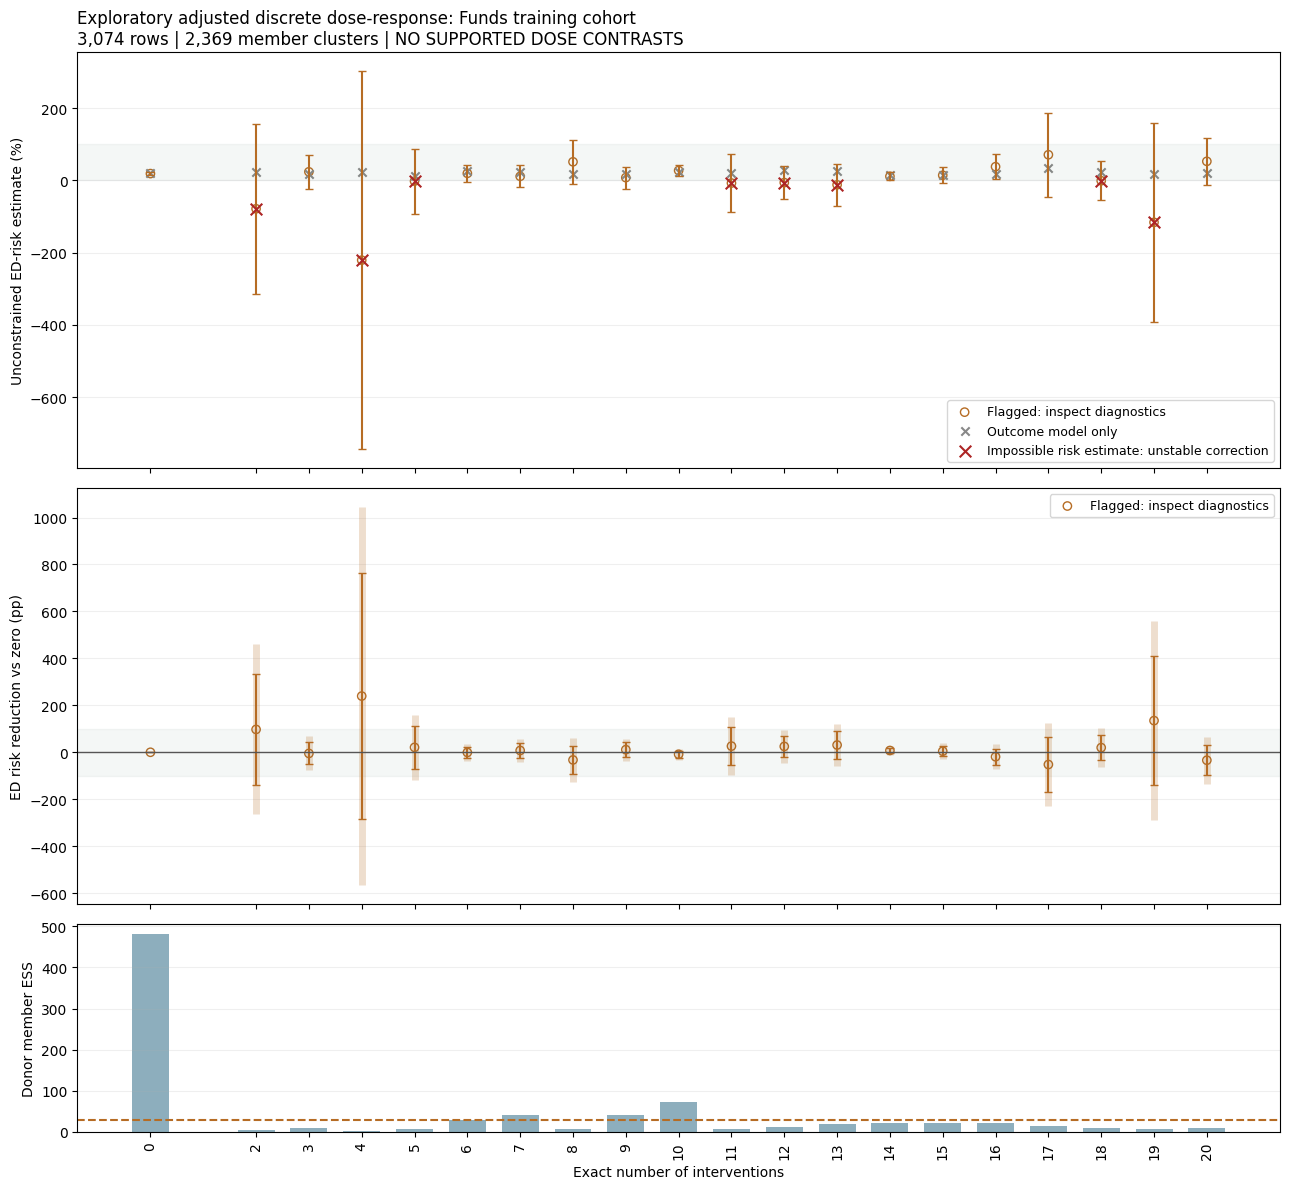

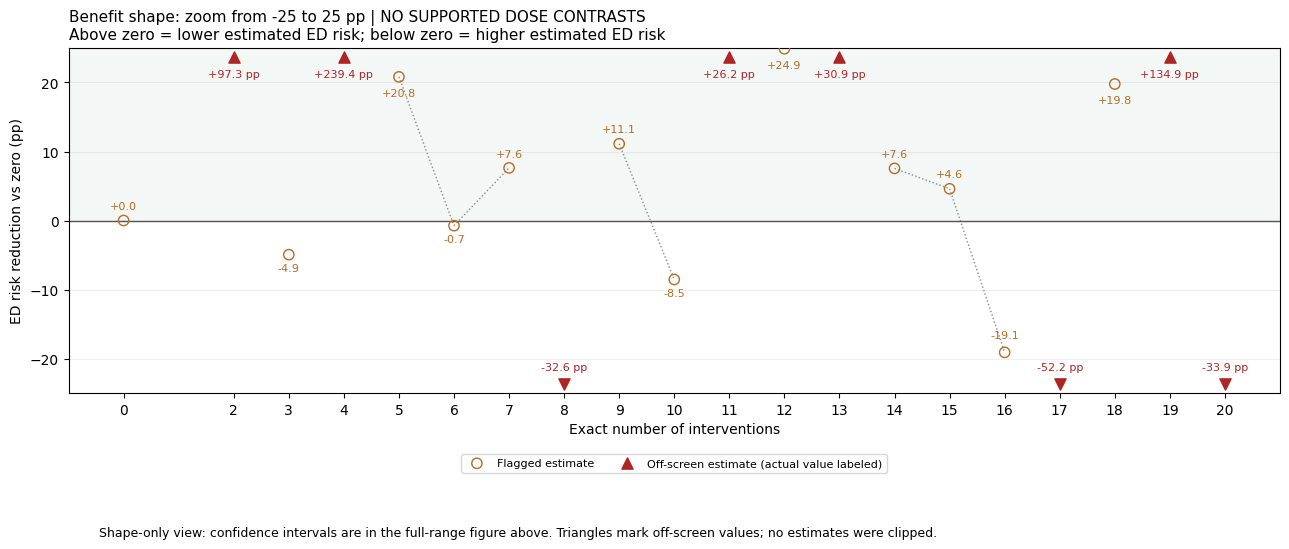

,from_dose,to_dose,additional_reduction_pp,ci_low_pp,ci_high_pp,sim_low_pp,sim_high_pp,pair_support_pass,small_increment_compatible
0,2,3,-102.259705,-341.929484,137.410073,-463.722530,259.203120,False,False
1,3,4,244.394729,-280.813193,769.602651,-547.708224,1036.497682,False,False
2,4,5,-218.630073,-749.465935,312.205790,-1019.220918,581.960772,False,False
3,5,6,-21.564622,-114.699785,71.570541,-162.028302,118.899058,False,False
4,6,7,8.372668,-30.467003,47.212339,-50.204168,66.949504,False,False
5,7,8,-40.212943,-107.870660,27.444773,-142.252298,61.826411,False,False
6,8,9,43.708728,-23.899630,111.317086,-58.256185,145.673641,False,False
7,9,10,-19.667300,-53.713514,14.378914,-71.014787,31.680186,False,False
8,10,11,34.712877,-47.371428,116.797182,-89.084228,158.509982,False,False
9,11,12,-1.277961,-94.012534,91.456613,-141.137483,138.581562,False,False


No automated optimal-dose recommendation is made.
An interval containing zero is inconclusive, not proof that benefit has plateaued.
The small-increment indicator requires a supported pair and its whole simultaneous interval within +/-1.0 percentage points; the margin needs substantive justification.


In [18]:
BENEFIT_ZOOM_LIMITS_PP = (-25.0, 25.0)  # Display range only; estimates are unchanged.
SHOW_ZOOM_INTERVALS = False  # Full uncertainty remains visible in the overview above.
label = 'Adjusted' if CONFIG['timing_confirmed'] else 'Exploratory adjusted'
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True,
                         gridspec_kw={'height_ratios': [2, 2, 1]})
for passed, color, marker in [(True, '#176b91', 'o'), (False, '#b66c24', 'o')]:
    mask = curve.contrast_pass.eq(passed)
    part = curve.loc[mask]
    if part.empty:
        continue
    name = 'Passes configured screens' if passed else 'Flagged: inspect diagnostics'
    face = color if passed else 'none'
    axes[0].errorbar(part.dose, 100 * part.ed_risk,
                     yerr=100 * np.vstack([part.ed_risk-part.risk_ci_low, part.risk_ci_high-part.ed_risk]),
                     fmt='none', ecolor=color, capsize=3)
    axes[0].scatter(part.dose, 100 * part.ed_risk, facecolors=face, edgecolors=color, label=name)
    axes[1].vlines(part.dose, part.benefit_sim_low_pp, part.benefit_sim_high_pp, color=color, alpha=.22, lw=5)
    axes[1].errorbar(part.dose, part.benefit_pp,
                     yerr=np.vstack([part.benefit_pp-part.benefit_ci_low_pp, part.benefit_ci_high_pp-part.benefit_pp]),
                     fmt='none', ecolor=color, capsize=3)
    axes[1].scatter(part.dose, part.benefit_pp, facecolors=face, edgecolors=color, label=name)
axes[0].scatter(curve.dose, 100 * curve.outcome_only_risk, marker='x', color='#888888', label='Outcome model only')
invalid = curve.loc[~curve.risk_in_bounds]
if len(invalid):
    axes[0].scatter(invalid.dose, 100 * invalid.ed_risk, marker='x', color='#ad2525',
                    s=70, zorder=5, label='Impossible risk estimate: unstable correction')
axes[0].axhspan(0, 100, color='#527f66', alpha=.06)
axes[0].set_ylabel('Unconstrained ED-risk estimate (%)')
screen_label = 'NO SUPPORTED DOSE CONTRASTS' if not curve.contrast_pass.any() else 'Inspect count-specific support flags'
axes[0].set_title(f'{label} discrete dose-response: Funds {CONFIG["population"]} cohort\n'
                  f'{len(analysis):,} rows | {analysis.member_id.nunique():,} member clusters | {screen_label}', loc='left')
axes[0].legend(fontsize=9)
axes[1].axhline(0, color='#555555', lw=1)
axes[1].axhspan(-100, 100, color='#527f66', alpha=.06)
axes[1].set_ylabel('ED risk reduction vs zero (pp)')
axes[1].legend(fontsize=9)
axes[2].bar(curve.dose, curve.member_ess, color='#8daebd', width=.7)
axes[2].axhline(CONFIG['minimum_member_ess'], color='#b66c24', ls='--')
axes[2].set(xlabel='Exact number of interventions', ylabel='Donor member ESS')
axes[2].set_xticks(curve.dose)
axes[2].tick_params(axis='x', rotation=90)
for ax in axes:
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()

# Separate shape view so large residual corrections cannot compress every other point.
low, high = map(float, BENEFIT_ZOOM_LIMITS_PP)
if not np.isfinite([low, high]).all() or not low < 0 < high:
    raise ValueError('Zoom limits must be finite and straddle zero.')
zoom_curve = curve.sort_values('dose').reset_index(drop=True)
inside = zoom_curve.benefit_pp.between(low, high)
zoom_fig, zoom_ax = plt.subplots(figsize=(13, 5.5))
zoom_ax.axhspan(0, high, color='#397d66', alpha=.06)
zoom_ax.axhline(0, color='#555555', lw=1)
for j in range(len(zoom_curve) - 1):
    a, b = zoom_curve.iloc[j], zoom_curve.iloc[j + 1]
    if b.dose == a.dose + 1 and inside.iloc[j] and inside.iloc[j + 1]:
        zoom_ax.plot([a.dose, b.dose], [a.benefit_pp, b.benefit_pp],
                     color='#8a8a8a', ls=':', lw=1, zorder=1)
for passed, color in [(True, '#176b91'), (False, '#b66c24')]:
    part = zoom_curve.loc[zoom_curve.contrast_pass.eq(passed)]
    visible = part.loc[part.benefit_pp.between(low, high)]
    if SHOW_ZOOM_INTERVALS:
        zoom_ax.vlines(part.dose, part.benefit_ci_low_pp, part.benefit_ci_high_pp,
                       color=color, alpha=.3, lw=1)
    if len(visible):
        zoom_ax.scatter(visible.dose, visible.benefit_pp, s=55, zorder=3,
                        facecolors=color if passed else 'none', edgecolors=color,
                        label='Passes screens' if passed else 'Flagged estimate')
        for row in visible.itertuples():
            label_offset = 8 if row.benefit_pp >= 0 else -12
            if row.benefit_pp > high - .12 * (high - low):
                label_offset = -14
            elif row.benefit_pp < low + .12 * (high - low):
                label_offset = 10
            zoom_ax.annotate(f'{row.benefit_pp:+.1f}', (row.dose, row.benefit_pp),
                             xytext=(0, label_offset),
                             textcoords='offset points', ha='center', fontsize=8, color=color)
outside = zoom_curve.loc[~inside & np.isfinite(zoom_curve.benefit_pp)]
padding = .025 * (high - low)
for j, row in enumerate(outside.itertuples()):
    above = row.benefit_pp > high
    boundary = high - padding if above else low + padding
    zoom_ax.scatter(row.dose, boundary, marker='^' if above else 'v', s=65,
                    color='#ad2525', zorder=4,
                    label='Off-screen estimate (actual value labeled)' if j == 0 else None)
    zoom_ax.annotate(f'{row.benefit_pp:+.1f} pp', (row.dose, boundary),
                     xytext=(0, -15 if above else 10), textcoords='offset points',
                     ha='center', fontsize=8, color='#ad2525')
zoom_ax.set_ylim(low, high)
zoom_ax.set_xticks(zoom_curve.dose)
zoom_ax.set(xlabel='Exact number of interventions', ylabel='ED risk reduction vs zero (pp)')
zoom_ax.set_title(f'Benefit shape: zoom from {low:g} to {high:g} pp | {screen_label}\n'
                  'Above zero = lower estimated ED risk; below zero = higher estimated ED risk', loc='left', fontsize=11)
zoom_ax.grid(axis='y', alpha=.2)
handles, labels = zoom_ax.get_legend_handles_labels()
if handles:
    zoom_ax.legend(handles, labels, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.16), ncol=3)
interval_note = ('Pointwise intervals shown; intervals may extend beyond this view.' if SHOW_ZOOM_INTERVALS
                 else 'Shape-only view: confidence intervals are in the full-range figure above.')
zoom_fig.text(.08, .015, f'{interval_note} Triangles mark off-screen values; no estimates were clipped.', fontsize=9)
zoom_fig.tight_layout(rect=[0, .08, 1, 1])
plt.show()

display(adjacent)
print('No automated optimal-dose recommendation is made.')
print('An interval containing zero is inconclusive, not proof that benefit has plateaued.')
print('The small-increment indicator requires a supported pair and its whole simultaneous interval within',
      f'+/-{CONFIG["small_increment_pp"]} percentage points; the margin needs substantive justification.')

## 8. Reproducible aggregate outputs and interpretation

Exports contain the cohort audit, all count frequencies, risk/benefit curve, adjacent-count
contrasts, covariate balance, fold diagnostics, sensitivity results, and input hashes/configuration.
Intervals are not clipped to probability bounds. Sparse counts remain in the count inventory
even though no effect is estimated there. An identified causal interpretation additionally
needs well-defined interventions, consistency, no interference, baseline confounding control,
valid temporal ordering, and positivity. Missing-to-zero outcomes assume missing records mean
no ED event; compare the complete-outcome sensitivity before using results.

Numerical tests live in `Code/test_funds_discrete_adrf.py`. They verify the discrete formula
against the general matrix correction, both double-robustness identities on a known probability
distribution, clustered covariance, and leakage-resistant preprocessing. These are Python
mathematical validation tests; R parity has not been executed.

In [19]:
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

if CONFIG['write_outputs']:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    exports = {
        'cohort_audit.csv': flow, 'count_inventory.csv': count_inventory,
        'dose_availability.csv': dose_availability,
        'discrete_adrf_curve.csv': curve, 'adjacent_count_benefit.csv': adjacent,
        'covariate_balance.csv': balance, 'crossfit_diagnostics.csv': main['audit'],
        'sensitivity_analysis.csv': sensitivity,
    }
    if sensitivity_audits:
        exports['sensitivity_crossfit_diagnostics.csv'] = pd.concat(sensitivity_audits, ignore_index=True)
    for name, table in exports.items():
        table.to_csv(OUTPUT_DIR / name, index=False)
    fig.savefig(OUTPUT_DIR / 'discrete_interventions_vs_ed_benefit.png', dpi=160, bbox_inches='tight')
    zoom_fig.savefig(OUTPUT_DIR / 'discrete_interventions_vs_ed_benefit_zoom.png', dpi=160, bbox_inches='tight')
    metadata = {
        'config': CONFIG, 'input_sha256': {str(p.relative_to(ROOT)): file_sha256(p) for p in (RAW_PATH, FULL_PATH, TEST_PATH)},
        'versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'nbformat']},
        'python': platform.python_version(), 'target_rows': len(analysis),
        'target_unique_members': int(analysis.member_id.nunique()), 'levels': levels.tolist(),
        'baseline_columns': NUMERIC_BASELINE + CATEGORICAL_BASELINE,
        'estimator': 'Galagate equation 3.7, discrete indicator basis, cross-fitted multi-arm AIPW',
        'r_parity': 'Mathematical adaptation; not a literal causaldrf aipwee_est port; R parity not executed',
        'inference': 'Member-cluster influence covariance and Gaussian multiplier simultaneous bands; no nuisance-refit bootstrap',
        'interpretation': label, 'estimand': 'row-average binary ED-event risk; benefit relative to exact count zero',
        'excluded_missing_counts': int(cohort.dose.isna().sum()),
        'supported_contrasts': int(curve.contrast_pass.sum()),
    }
    (OUTPUT_DIR / 'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    print('Saved aggregate results to', OUTPUT_DIR)
run_summary = pd.DataFrame({
    'check': ['source cohort/split validation', 'analysis rows', 'missing-count exclusions',
              'dose-versus-zero contrasts passing screens', 'unbounded risk estimates',
              'timing confirmed', 'automatic optimal dose'],
    'result': ['passed', len(analysis), int(cohort.dose.isna().sum()),
               int(curve.contrast_pass.sum()), int((~curve.risk_in_bounds).sum()),
               CONFIG['timing_confirmed'], 'not established'],
})
display(run_summary)
print('Complete. Review support flags and sensitivity results before interpreting the curve.')

Saved aggregate results to C:\Users\i.Nikesh.Desai\OneDrive - Acentra\Documents\GitHub\prism_repo\Outputs\Discrete_ADRF_Funds\Python\training


,check,result
0,source cohort/split validation,passed
1,analysis rows,3074
2,missing-count exclusions,1378
3,dose-versus-zero contrasts passing screens,0
4,unbounded risk estimates,8
5,timing confirmed,False
6,automatic optimal dose,not established


Complete. Review support flags and sensitivity results before interpreting the curve.


## 9. Binned intervention analysis: 0, 1–5, 6–10, 11–15, 16–20, 21+

This additional analysis uses the **same known-count population, binary 90-day ED outcome,
baseline covariates, and missing-outcome rules** as the exact-count analysis above. Zero remains
its own reference group. Missing counts remain excluded; they are never assigned to zero.
Every known count is assigned to one of the six fixed groups, including the previously sparse
high counts. Boundaries are fixed in advance and are not selected using benefit estimates.

We **refit** the multinomial exposure model and each group's outcome model using these groups.
We do not average exact-count effects or reuse exact-count propensity scores. In the same
residual-correction equation, $I(T=t)$ becomes $I(G=g)$ and the denominator becomes
$P(G=g\mid X)$. Codes 0–5 are category labels used internally, not numeric intervention counts.
Exact count, group label, and treatment flags are not included among baseline confounders.

Each point is the standardized mean for a **range of counts**, relative to zero. It cannot
identify the effect of an exact count within that range. Its causal interpretation depends on
specifying the mix of counts/interventions within a group (or assuming that those versions
have equivalent effects). The open-ended 21+ group is particularly heterogeneous. See
[treatment-version considerations](https://pmc.ncbi.nlm.nih.gov/articles/PMC3805254/).
Binning does not resolve missingness, temporal ordering, or unmeasured confounding.

In [20]:
BIN_CONFIG = CONFIG.copy()  # Same estimator settings and diagnostic thresholds.
BIN_LABELS = dict(enumerate(INTERVENTION_BIN_LABELS))
BIN_LEVELS = np.arange(6, dtype=int)
BIN_OUTPUT_DIR = OUTPUT_DIR / 'binned'
binned_analysis = analysis.copy()
binned_analysis['exact_intervention_count'] = binned_analysis['dose']
binned_analysis['dose'] = bin_intervention_counts(binned_analysis['exact_intervention_count']).astype(int)
binned_analysis['intervention_bin'] = binned_analysis.dose.map(BIN_LABELS)
if not binned_analysis.analysis_row_id.equals(analysis.analysis_row_id):
    raise AssertionError('Binning changed the target row order.')
if not binned_analysis.ed_event_90d.equals(analysis.ed_event_90d):
    raise AssertionError('Binning changed the outcome.')
if set(binned_analysis.dose) != set(BIN_LEVELS):
    raise ValueError('One or more requested bins are empty; cannot estimate all six groups.')
bin_inventory = binned_analysis.groupby('dose').agg(
    rows=('dose', 'size'), unique_members=('member_id', 'nunique'),
    min_observed_count=('exact_intervention_count', 'min'),
    max_observed_count=('exact_intervention_count', 'max'),
    observed_events=('ed_event_90d', 'sum'), observed_risk=('ed_event_90d', 'mean'),
    missing_outcomes=('outcome_missing_filled_zero', 'sum'),
    flag_disagreements=('flag_count_inconsistent', 'sum'),
).reset_index().rename(columns={'dose': 'bin_code'})
bin_inventory.insert(1, 'intervention_bin', bin_inventory.bin_code.map(BIN_LABELS))
bin_inventory['below_member_threshold'] = bin_inventory.unique_members.lt(BIN_CONFIG['minimum_dose_members'])
display(bin_inventory)
print('All six bins retained; groups with weak support will be flagged, never silently merged.')
print('Target rows:', len(binned_analysis), '| target members:', binned_analysis.member_id.nunique())
print('Member counts across bins are not additive: repeated members can occur in multiple bins.')

,bin_code,intervention_bin,rows,unique_members,min_observed_count,max_observed_count,observed_events,observed_risk,missing_outcomes,flag_disagreements,below_member_threshold
0,0,0,762,761,0,0,145,0.190289,70,1,False
1,1,1-5,298,225,1,5,57,0.191275,9,63,False
2,2,6-10,730,562,6,10,152,0.208219,14,67,False
3,3,11-15,595,428,11,15,139,0.233613,16,34,False
4,4,16-20,305,211,16,20,76,0.249180,9,15,False
5,5,21+,384,216,21,71,125,0.325521,36,16,False


All six bins retained; groups with weak support will be flagged, never silently merged.
Target rows: 3074 | target members: 2369
Member counts across bins are not additive: repeated members can occur in multiple bins.


### Refit and evaluate the binned model

Group-aware folds are reconstructed for the six-category treatment; a member never occurs in
both the fitting and prediction portion of a fold. All treatment probabilities are probabilities
of a **bin**, and the six probabilities sum to one. Diagnostics retain the same thresholds as
the exact-count analysis. Neighboring-bin contrasts compare ranges, **not one extra intervention**.
Confidence intervals use the same member-clustered score approximation and simultaneous bands.

In [21]:
with threadpool_limits(limits=2):
    binned_main = fit_discrete_adrf(binned_analysis, BIN_LEVELS, BIN_CONFIG)
    binned_curve, binned_adjacent, binned_balance = summarize_result(binned_main, BIN_CONFIG)
if not np.allclose(binned_main['p'].sum(axis=1), 1, atol=1e-8):
    raise AssertionError('Bin probabilities do not sum to one.')
bin_folds = pd.DataFrame({'member': binned_analysis.member_id, 'fold': binned_main['fold']})
if bin_folds.groupby('member').fold.nunique().gt(1).any():
    raise AssertionError('Repeated member crosses bin-model prediction folds.')
# Public tables carry range labels, so internal category codes cannot be mistaken for counts.
binned_curve = binned_curve.rename(columns={'dose': 'bin_code'})
binned_curve.insert(1, 'intervention_bin', binned_curve.bin_code.map(BIN_LABELS))
binned_balance = binned_balance.rename(columns={'dose': 'bin_code'})
binned_balance.insert(1, 'intervention_bin', binned_balance.bin_code.map(BIN_LABELS))
binned_fold_audit = binned_main['audit'].rename(columns={'dose': 'bin_code'})
binned_fold_audit.insert(1, 'intervention_bin', binned_fold_audit.bin_code.map(BIN_LABELS))
binned_adjacent = binned_adjacent.rename(columns={
    'from_dose': 'from_bin_code', 'to_dose': 'to_bin_code',
    'additional_reduction_pp': 'between_bin_reduction_pp',
    'small_increment_compatible': 'small_between_bin_difference_compatible',
})
binned_adjacent.insert(1, 'from_bin', binned_adjacent.from_bin_code.map(BIN_LABELS))
binned_adjacent.insert(3, 'to_bin', binned_adjacent.to_bin_code.map(BIN_LABELS))
display(binned_curve[['intervention_bin', 'observed_rows', 'observed_members',
                      'propensity_min', 'member_ess', 'outcome_only_risk', 'residual_correction',
                      'ed_risk', 'benefit_pp', 'benefit_ci_low_pp', 'benefit_ci_high_pp',
                      'max_abs_smd', 'support_flags', 'contrast_pass']])
display(binned_adjacent)
bin_comparison = pd.DataFrame([
    {'analysis': name, 'target_rows': len(analysis), 'positive_groups': int((table[code] > 0).sum()),
     'positive_contrasts_passing': int(table.loc[table[code] > 0, 'contrast_pass'].sum()),
     'minimum_positive_member_ess': table.loc[table[code] > 0, 'member_ess'].min(),
     'median_positive_member_ess': table.loc[table[code] > 0, 'member_ess'].median(),
     'maximum_absolute_residual_correction': table.residual_correction.abs().max(),
     'risk_estimates_outside_01': int((~table.risk_in_bounds).sum())}
    for name, table, code in [('Exact counts', curve, 'dose'), ('Six fixed bins', binned_curve, 'bin_code')]
])
display(bin_comparison)
print('Binning changes the estimand; this table compares stability, not equivalent treatment effects.')

Fold 1/5: 2,459 fitting rows, 615 held-out rows


Fold 2/5: 2,460 fitting rows, 614 held-out rows


Fold 3/5: 2,458 fitting rows, 616 held-out rows


Fold 4/5: 2,459 fitting rows, 615 held-out rows


Fold 5/5: 2,460 fitting rows, 614 held-out rows


,intervention_bin,observed_rows,observed_members,propensity_min,member_ess,outcome_only_risk,residual_correction,ed_risk,benefit_pp,benefit_ci_low_pp,benefit_ci_high_pp,max_abs_smd,support_flags,contrast_pass
0,0,762,761,4.040227e-07,451.935567,0.190961,0.006897,0.197858,0.000000,0.000000,0.000000,0.247920,residual covariate imbalance,False
1,1-5,298,225,5.166898e-05,1.488235,0.207614,-0.699155,-0.491541,68.939860,-86.772437,224.652157,11.964850,low member ESS; residual covariate imbalance; ...,False
2,6-10,730,562,3.605695e-03,52.154463,0.223690,-0.190838,0.032852,16.500589,-19.245757,52.246934,3.554649,residual covariate imbalance; dominant donor m...,False
3,11-15,595,428,1.468642e-03,234.867124,0.235547,0.005454,0.241001,-4.314351,-11.522825,2.894123,1.022313,residual covariate imbalance,False
4,16-20,305,211,1.092144e-04,129.356688,0.243890,-0.035349,0.208541,-1.068378,-11.032701,8.895945,0.344732,residual covariate imbalance,False
5,21+,384,216,8.676102e-05,76.312879,0.245804,-0.013972,0.231832,-3.397420,-16.481195,9.686354,0.736369,residual covariate imbalance,False


,from_bin_code,from_bin,to_bin_code,to_bin,between_bin_reduction_pp,ci_low_pp,ci_high_pp,sim_low_pp,sim_high_pp,pair_support_pass,small_between_bin_difference_compatible
0,0,0,1,1-5,68.939860,-86.772437,224.652157,-136.485713,274.365433,False,False
1,1,1-5,2,6-10,-52.439271,-212.245093,107.366551,-263.265283,158.386741,False,False
2,2,6-10,3,11-15,-20.814939,-56.895577,15.265698,-68.414813,26.784934,False,False
3,3,11-15,4,16-20,3.245973,-7.760078,14.252023,-11.273910,17.765855,False,False
4,4,16-20,5,21+,-2.329042,-17.885769,13.227685,-22.852467,18.194383,False,False


,analysis,target_rows,positive_groups,positive_contrasts_passing,minimum_positive_member_ess,median_positive_member_ess,maximum_absolute_residual_correction,risk_estimates_outside_01
0,Exact counts,3074,19,0,1.445991,12.299568,2.451047,8
1,Six fixed bins,3074,5,0,1.488235,76.312879,0.699155,1


Binning changes the estimand; this table compares stability, not equivalent treatment effects.


### Binned sensitivity analyses

These checks repeat the original sensitivity designs using freshly estimated **bin-level**
nuisance models. The observed-outcome-only and consistent-flag-only analyses change the target
population; their differences must not be interpreted purely as changes in estimation bias.
Probability floors are labeled sensitivity estimates and never replace the unfloored main result.

In [22]:
binned_sensitivity_tables, binned_sensitivity_audits = [], []
for floor in [None, 0.005, 0.01, 0.02]:
    scores = discrete_scores(binned_analysis.ed_event_90d.to_numpy(), binned_analysis.dose.to_numpy(),
                             BIN_LEVELS, binned_main['m'], binned_main['p'], floor=floor)
    risks = scores.mean(axis=0)
    binned_sensitivity_tables.append(pd.DataFrame({
        'scenario': 'main_unfloored' if floor is None else f'propensity_floor_{floor}',
        'bin_code': BIN_LEVELS, 'ed_risk': risks, 'benefit_pp': 100 * (risks[0] - risks),
        'target_rows': len(binned_analysis), 'status': 'completed',
    }))
if BIN_CONFIG['run_sensitivities']:
    bin_scenarios = [
        ('linear_probability_ridge', binned_analysis, BIN_CONFIG, 'ridge'),
        ('stronger_regularization', binned_analysis,
         {**BIN_CONFIG, 'propensity_C': 0.05, 'outcome_C': 0.05}, 'logistic'),
        ('observed_outcomes_only_changed_target',
         binned_analysis.loc[~binned_analysis.outcome_missing_filled_zero], BIN_CONFIG, 'logistic'),
        ('consistent_flags_only_changed_target',
         binned_analysis.loc[~binned_analysis.flag_count_inconsistent], BIN_CONFIG, 'logistic'),
    ]
    for name, subset, cfg, model in bin_scenarios:
        print('Binned sensitivity:', name, flush=True)
        try:
            with threadpool_limits(limits=2):
                bin_fit = fit_discrete_adrf(subset, BIN_LEVELS, cfg, outcome_model=model, verbose=False)
                bin_summary, _, _ = summarize_result(bin_fit, cfg)
            bin_summary = bin_summary.rename(columns={'dose': 'bin_code'})
            bin_summary['scenario'], bin_summary['target_rows'], bin_summary['status'] = name, len(subset), 'completed'
            binned_sensitivity_tables.append(bin_summary)
            binned_sensitivity_audits.append(bin_fit['audit'].rename(columns={'dose': 'bin_code'}).assign(scenario=name))
        except (ValueError, np.linalg.LinAlgError, ConvergenceWarning) as exc:
            binned_sensitivity_tables.append(pd.DataFrame({'scenario': [name], 'status': [f'FAILED: {exc}'],
                                                           'target_rows': [len(subset)]}))
            print('Binned sensitivity could not be estimated:', exc)
binned_sensitivity = pd.concat(binned_sensitivity_tables, ignore_index=True)
binned_sensitivity.insert(1, 'intervention_bin', binned_sensitivity.bin_code.map(BIN_LABELS))
display(binned_sensitivity.pivot_table(index='bin_code', columns='scenario', values='benefit_pp')
        .rename(index=BIN_LABELS).rename_axis('intervention_bin'))
display(binned_sensitivity[['scenario', 'status', 'target_rows']].drop_duplicates())

Binned sensitivity: linear_probability_ridge


Binned sensitivity: stronger_regularization


Binned sensitivity: observed_outcomes_only_changed_target


Binned sensitivity: consistent_flags_only_changed_target


scenario,consistent_flags_only_changed_target,linear_probability_ridge,main_unfloored,observed_outcomes_only_changed_target,propensity_floor_0.005,propensity_floor_0.01,propensity_floor_0.02,stronger_regularization
intervention_bin,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1-5,286.495354,425.060870,68.939860,77.211464,-4.358375,-4.563225,-1.132351,7.876529
6-10,22.520144,23.779597,16.500589,27.035613,11.471623,4.969131,1.717885,8.271823
11-15,-11.123299,-2.515106,-4.314351,-3.180283,-4.314351,-4.314351,-4.063127,-4.685662
16-20,-5.888598,0.309080,-1.068378,-4.109190,-1.068378,-1.068378,-1.068378,-1.837374
21+,-8.871608,-2.550278,-3.397420,-0.836383,-3.406224,-5.493013,-6.623508,-6.161154


,scenario,status,target_rows
0,main_unfloored,completed,3074
6,propensity_floor_0.005,completed,3074
12,propensity_floor_0.01,completed,3074
18,propensity_floor_0.02,completed,3074
24,linear_probability_ridge,completed,3074
30,stronger_regularization,completed,3074
36,observed_outcomes_only_changed_target,completed,2920
42,consistent_flags_only_changed_target,completed,2878


### Binned ED risk and benefit curves

The x-axis contains category labels, with equal spacing for readability; the last category
means **21 or more** and has no assigned midpoint. Points show population-average estimates.
Error bars show pointwise 95% intervals; thick translucent lines show simultaneous benefit
intervals. Dotted connections are visual guides between category estimates, not interpolation
between exact counts. Positive benefit means lower ED risk than the zero-intervention group.
The same diagnostic flags remain visible, including any problem with the zero reference.

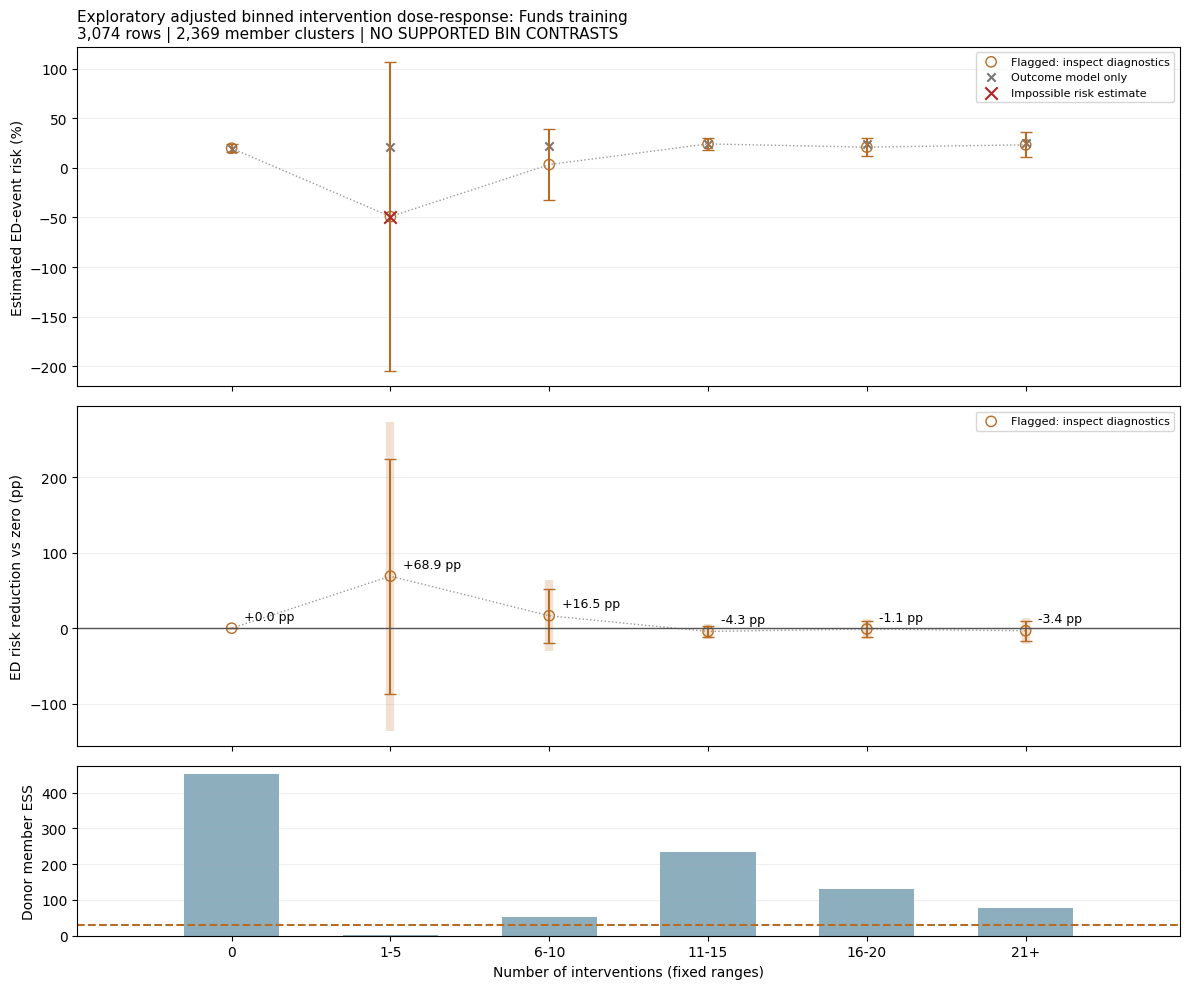

Positive bin-versus-zero contrasts passing all screens: 0 of 5
A more stable curve is not proof of causal identification or an optimal intervention count.


In [23]:
bin_screen_label = ('NO SUPPORTED BIN CONTRASTS' if not binned_curve.loc[binned_curve.bin_code > 0, 'contrast_pass'].any()
                    else 'Inspect bin-specific support flags')
binned_fig, bin_axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True,
                                    gridspec_kw={'height_ratios': [2, 2, 1]})
bin_axes[0].plot(binned_curve.bin_code, 100 * binned_curve.ed_risk, ':', color='#999999', lw=1)
bin_axes[1].plot(binned_curve.bin_code, binned_curve.benefit_pp, ':', color='#999999', lw=1)
for passed, color in [(True, '#176b91'), (False, '#b66c24')]:
    part = binned_curve.loc[binned_curve.contrast_pass.eq(passed)]
    if part.empty:
        continue
    name = 'Passes configured screens' if passed else 'Flagged: inspect diagnostics'
    face = color if passed else 'none'
    bin_axes[0].errorbar(part.bin_code, 100 * part.ed_risk,
                         yerr=100 * np.vstack([part.ed_risk-part.risk_ci_low, part.risk_ci_high-part.ed_risk]),
                         fmt='none', ecolor=color, capsize=4)
    bin_axes[0].scatter(part.bin_code, 100 * part.ed_risk, facecolors=face, edgecolors=color, s=55, label=name)
    bin_axes[1].vlines(part.bin_code, part.benefit_sim_low_pp, part.benefit_sim_high_pp, color=color, alpha=.2, lw=6)
    bin_axes[1].errorbar(part.bin_code, part.benefit_pp,
                         yerr=np.vstack([part.benefit_pp-part.benefit_ci_low_pp, part.benefit_ci_high_pp-part.benefit_pp]),
                         fmt='none', ecolor=color, capsize=4)
    bin_axes[1].scatter(part.bin_code, part.benefit_pp, facecolors=face, edgecolors=color, s=55, label=name)
bin_axes[0].scatter(binned_curve.bin_code, 100 * binned_curve.outcome_only_risk,
                    marker='x', color='#777777', label='Outcome model only')
bin_invalid = binned_curve.loc[~binned_curve.risk_in_bounds]
if len(bin_invalid):
    bin_axes[0].scatter(bin_invalid.bin_code, 100 * bin_invalid.ed_risk, marker='x', color='#ad2525',
                        s=80, zorder=5, label='Impossible risk estimate')
for row in binned_curve.itertuples():
    bin_axes[1].annotate(f'{row.benefit_pp:+.1f} pp', (row.bin_code, row.benefit_pp),
                         xytext=(9, 6), textcoords='offset points', fontsize=9)
bin_axes[0].set_ylabel('Estimated ED-event risk (%)')
bin_axes[0].set_title(f'{label} binned intervention dose-response: Funds {CONFIG["population"]}\n'
                      f'{len(binned_analysis):,} rows | {binned_analysis.member_id.nunique():,} member clusters | {bin_screen_label}',
                      loc='left', fontsize=11)
bin_axes[0].legend(fontsize=8)
bin_axes[1].axhline(0, color='#555555', lw=1)
bin_axes[1].set_ylabel('ED risk reduction vs zero (pp)')
bin_axes[1].legend(fontsize=8)
bin_axes[2].bar(binned_curve.bin_code, binned_curve.member_ess, width=.6, color='#8daebd')
bin_axes[2].axhline(BIN_CONFIG['minimum_member_ess'], ls='--', color='#b66c24')
bin_axes[2].set_xticks(BIN_LEVELS, [BIN_LABELS[i] for i in BIN_LEVELS])
bin_axes[2].set(xlabel='Number of interventions (fixed ranges)', ylabel='Donor member ESS')
for ax in bin_axes:
    ax.grid(axis='y', alpha=.2)
    ax.margins(x=.12)
binned_fig.tight_layout()
plt.show()
print('Positive bin-versus-zero contrasts passing all screens:',
      int(binned_curve.loc[binned_curve.bin_code > 0, 'contrast_pass'].sum()), 'of 5')
print('A more stable curve is not proof of causal identification or an optimal intervention count.')

In [24]:
if CONFIG['write_outputs']:
    BIN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    bin_exports = {
        'bin_inventory.csv': bin_inventory, 'binned_adrf_curve.csv': binned_curve,
        'neighboring_bin_benefit.csv': binned_adjacent, 'binned_covariate_balance.csv': binned_balance,
        'binned_crossfit_diagnostics.csv': binned_fold_audit,
        'binned_sensitivity_analysis.csv': binned_sensitivity,
        'exact_vs_binned_stability.csv': bin_comparison,
    }
    if binned_sensitivity_audits:
        bin_audits = pd.concat(binned_sensitivity_audits, ignore_index=True)
        bin_audits.insert(1, 'intervention_bin', bin_audits.bin_code.map(BIN_LABELS))
        bin_exports['binned_sensitivity_crossfit_diagnostics.csv'] = bin_audits
    for filename, table in bin_exports.items():
        table.to_csv(BIN_OUTPUT_DIR / filename, index=False)
    binned_fig.savefig(BIN_OUTPUT_DIR / 'binned_interventions_vs_ed_benefit.png', dpi=160, bbox_inches='tight')
    bin_metadata = {
        **metadata, 'config': BIN_CONFIG, 'levels': BIN_LEVELS.tolist(),
        'bin_labels': BIN_LABELS, 'bin_upper_boundaries': [0, 5, 10, 15, 20, None],
        'bin_rule': '0; 1-5; 6-10; 11-15; 16-20; 21 and above. Nonnegative integers only.',
        'estimand': 'Row-average binary ED-event risk by intervention-count range; benefit versus the zero bin',
        'estimator': 'Cross-fitted six-category AIPW, both nuisance models refitted for bins',
        'same_target_as_exact_counts': True,
        'supported_contrasts': int(binned_curve.loc[binned_curve.bin_code > 0, 'contrast_pass'].sum()),
        'contrast_count_excludes_reference': True,
        'within_bin_interpretation': 'Requires a defined mixture of intervention versions or version-irrelevance assumptions',
    }
    (BIN_OUTPUT_DIR / 'binned_run_metadata.json').write_text(json.dumps(bin_metadata, indent=2), encoding='utf-8')
    print('Saved binned aggregate results to', BIN_OUTPUT_DIR)

Saved binned aggregate results to C:\Users\i.Nikesh.Desai\OneDrive - Acentra\Documents\GitHub\prism_repo\Outputs\Discrete_ADRF_Funds\Python\training\binned
